DAY 5: RAYLEIGH-NUMBER COMPARISON
----------------------------------------------------------------------------------------
 Ra      time       steps       max|u|       max|w|       max speed
  500   0.02500       800   0.0056598   0.011284   0.011284
 1000   0.02500       800   0.0092607   0.018427   0.018427
 2500   0.02500       800   0.012688   0.025056   0.025056
 5000   0.02500       800   0.0093547   0.01817   0.01817


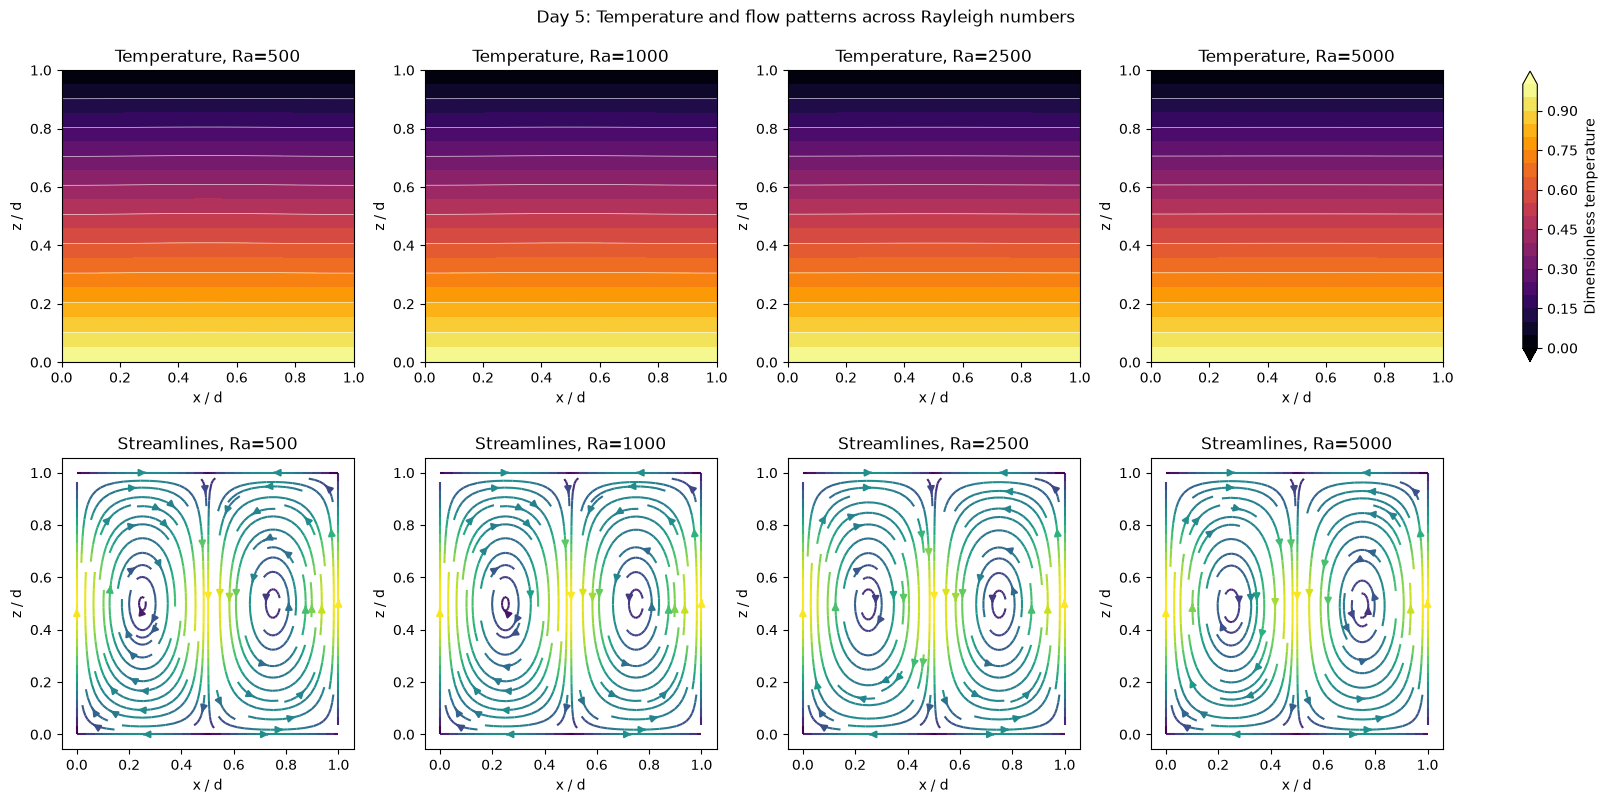

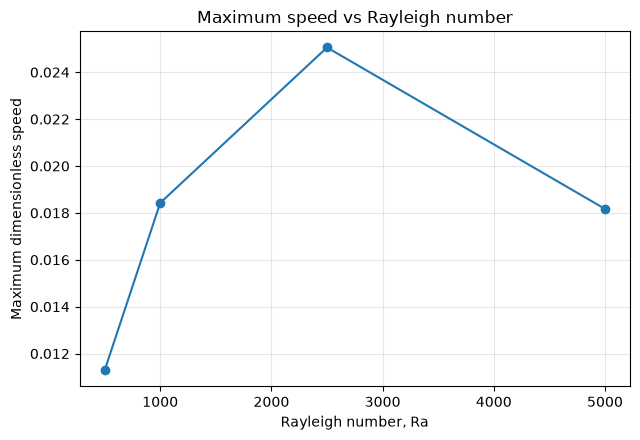

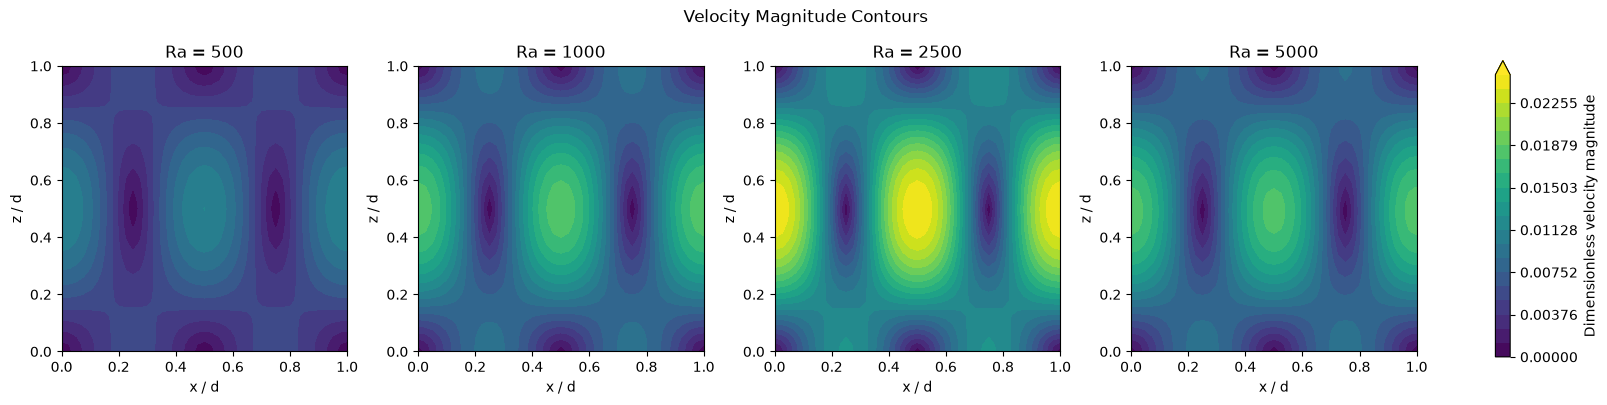

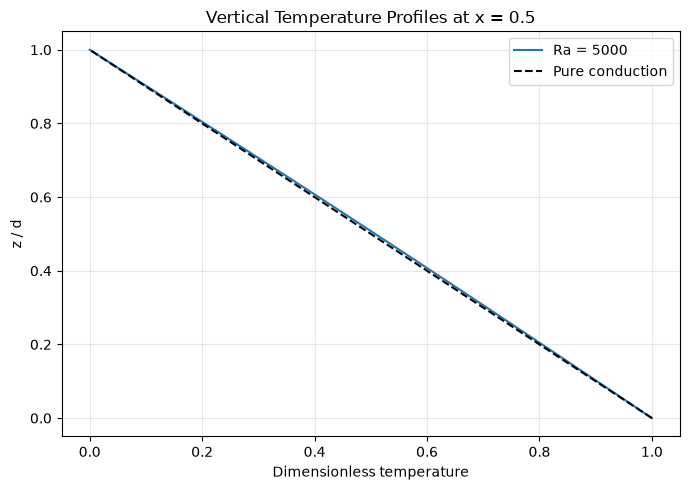


Saved files in: C:\Users\athil\OneDrive\Desktop\day5_results
Give the .npz files and day5_summary.csv to Person 3.

Reminder: this is a simplified 2-D Boussinesq model with stress-free-style streamfunction boundaries, not a full spherical mantle simulation. Check grid/time convergence before interpreting the comparison quantitatively.


In [5]:
"""
Day 5: Rayleigh-number comparison for a simplified 2-D mantle-convection model.

Requirements:
    pip install numpy matplotlib scipy

Model:
- Unit square, dimensionless thermal diffusivity = 1
- Hot bottom T=1, cold top T=0
- Insulating sidewalls
- Infinite-Prandtl Stokes streamfunction equation:
      ∇⁴ψ = -Ra * ∂T/∂x
  with stress-free-style streamfunction conditions ψ=0 and ∇²ψ=0
  on the walls, approximated by the discrete biharmonic operator.
- Temperature equation:
      ∂T/∂t + u ∂T/∂x + w ∂T/∂z = ∇²T
  where u=∂ψ/∂z and w=-∂ψ/∂x.

This is a simplified educational 2-D model, not a full spherical-Earth simulation.
"""

import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import factorized


# ------------------------- Settings -------------------------

N = 41
RA_VALUES = [500.0, 1000.0, 2500.0, 5000.0]
END_TIME = 0.025
SAFETY_DIFFUSION = 0.20
SAFETY_ADVECTION = 0.30
OUTPUT_DIR = Path("day5_results")
OUTPUT_DIR.mkdir(exist_ok=True)


# ------------------------- Basic numerical functions -------------------------

def laplacian(a, dx, dz):
    """Return ∇²a at interior points only."""
    return (
        (a[1:-1, 2:] - 2*a[1:-1, 1:-1] + a[1:-1, :-2]) / dx**2
        + (a[2:, 1:-1] - 2*a[1:-1, 1:-1] + a[:-2, 1:-1]) / dz**2
    )


def make_biharmonic_solver(n, dx, dz):
    """
    Build a reusable sparse solver for the discrete biharmonic equation.

    Applying the discrete Laplacian twice gives the biharmonic operator.
    The boundary values of psi are zero; this corresponds to a simplified
    stress-free-style streamfunction boundary treatment for this prototype.
    """
    m = n - 2  # interior points per direction

    main_x = -2.0 / dx**2 * np.ones(m)
    off_x = 1.0 / dx**2 * np.ones(m - 1)
    Dxx = diags([off_x, main_x, off_x], [-1, 0, 1], format="csc")

    main_z = -2.0 / dz**2 * np.ones(m)
    off_z = 1.0 / dz**2 * np.ones(m - 1)
    Dzz = diags([off_z, main_z, off_z], [-1, 0, 1], format="csc")

    I = eye(m, format="csc")
    lap = kron(I, Dxx, format="csc") + kron(Dzz, I, format="csc")
    biharmonic = (lap @ lap).tocsc()

    # Factorize once; reuse for every time step for this grid.
    solve = factorized(biharmonic)
    return solve


def solve_streamfunction(T, ra, dx, dz, solve_biharmonic):
    """Solve ∇⁴ψ = -Ra*dT/dx and return psi."""
    n = T.shape[0]
    dTdx = np.gradient(T, dx, axis=1)

    rhs = -ra * dTdx[1:-1, 1:-1]
    psi = np.zeros_like(T)
    psi[1:-1, 1:-1] = solve_biharmonic(rhs.ravel()).reshape(n - 2, n - 2)
    return psi


def velocity_from_streamfunction(psi, dx, dz):
    """u=dpsi/dz and w=-dpsi/dx."""
    u = np.gradient(psi, dz, axis=0)
    w = -np.gradient(psi, dx, axis=1)
    return u, w


def apply_temperature_boundaries(T):
    """Fixed hot/cold horizontal boundaries and insulated vertical walls."""
    T[0, :] = 1.0
    T[-1, :] = 0.0
    T[1:-1, 0] = T[1:-1, 1]
    T[1:-1, -1] = T[1:-1, -2]
    # Keep corner values consistent with the fixed top/bottom boundaries.
    T[0, :] = 1.0
    T[-1, :] = 0.0
    return T


# ------------------------- One simulation -------------------------

def run_one_rayleigh(ra, x, z, end_time):
    n = len(x)
    dx = x[1] - x[0]
    dz = z[1] - z[0]
    X, Z = np.meshgrid(x, z)

    # Initial conductive profile plus a small smooth disturbance.
    T = 1.0 - Z + 0.015 * np.sin(np.pi * X) * np.sin(np.pi * Z)
    T = apply_temperature_boundaries(T)

    solve_biharmonic = make_biharmonic_solver(n, dx, dz)

    dt_diff = SAFETY_DIFFUSION / (
        2.0 * (1.0 / dx**2 + 1.0 / dz**2)
    )

    t = 0.0
    step = 0

    while t < end_time:
        psi = solve_streamfunction(T, ra, dx, dz, solve_biharmonic)
        u, w = velocity_from_streamfunction(psi, dx, dz)

        speed = max(
            float(np.max(np.abs(u))),
            float(np.max(np.abs(w))),
            1e-12
        )
        dt_adv = SAFETY_ADVECTION * min(dx, dz) / speed
        dt = min(dt_diff, dt_adv, end_time - t)

        # Upwind temperature gradients at interior points.
        uc = u[1:-1, 1:-1]
        wc = w[1:-1, 1:-1]
        Tc = T[1:-1, 1:-1]

        tx = np.where(
            uc >= 0.0,
            (Tc - T[1:-1, :-2]) / dx,
            (T[1:-1, 2:] - Tc) / dx
        )
        tz = np.where(
            wc >= 0.0,
            (Tc - T[:-2, 1:-1]) / dz,
            (T[2:, 1:-1] - Tc) / dz
        )

        T_new = T.copy()
        T_new[1:-1, 1:-1] = Tc + dt * (
            -uc * tx - wc * tz + laplacian(T, dx, dz)
        )
        T = apply_temperature_boundaries(T_new)

        t += dt
        step += 1

        if step > 300000:
            raise RuntimeError(
                f"Ra={ra:g}: exceeded 300000 steps; inspect stability."
            )

    # Recompute final flow from final temperature.
    psi = solve_streamfunction(T, ra, dx, dz, solve_biharmonic)
    u, w = velocity_from_streamfunction(psi, dx, dz)
    speed = np.hypot(u, w)
    density_anomaly = -(T - 0.5)

    return {
        "ra": ra,
        "x": x,
        "z": z,
        "X": X,
        "Z": Z,
        "T": T,
        "psi": psi,
        "u": u,
        "w": w,
        "speed": speed,
        "density_anomaly": density_anomaly,
        "time": t,
        "steps": step,
        "max_u": float(np.max(np.abs(u))),
        "max_w": float(np.max(np.abs(w))),
        "max_speed": float(np.max(speed)),
    }


# ------------------------- Main Day-5 experiment -------------------------

def main():
    x = np.linspace(0.0, 1.0, N)
    z = np.linspace(0.0, 1.0, N)

    results = []
    print("DAY 5: RAYLEIGH-NUMBER COMPARISON")
    print("-" * 88)
    print(" Ra      time       steps       max|u|       max|w|       max speed")

    for ra in RA_VALUES:
        result = run_one_rayleigh(ra, x, z, END_TIME)
        results.append(result)

        print(
            f"{ra:5.0f}   {result['time']:.5f}   "
            f"{result['steps']:7d}   {result['max_u']:.5g}   "
            f"{result['max_w']:.5g}   {result['max_speed']:.5g}"
        )

        # Save all fields for Person 3.
        np.savez_compressed(
            OUTPUT_DIR / f"mantle_Ra_{int(ra)}.npz",
            x=result["x"],
            z=result["z"],
            T=result["T"],
            psi=result["psi"],
            u=result["u"],
            w=result["w"],
            speed=result["speed"],
            density_anomaly=result["density_anomaly"],
            ra=result["ra"],
            time=result["time"],
            steps=result["steps"],
            max_u=result["max_u"],
            max_w=result["max_w"],
            max_speed=result["max_speed"],
        )

    # Summary CSV
    with open(OUTPUT_DIR / "day5_summary_new.csv", "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "Ra", "grid", "final_time", "steps",
            "max_abs_u", "max_abs_w", "max_speed"
        ])
        for r in results:
            writer.writerow([
                r["ra"], f"{N}x{N}", r["time"], r["steps"],
                r["max_u"], r["max_w"], r["max_speed"]
            ])

    # Comparison plot: one temperature panel and one streamline panel per Ra.
    fig, axes = plt.subplots(
        2, len(results), figsize=(4 * len(results), 8),
        constrained_layout=True
    )

    for j, r in enumerate(results):
        axT = axes[0, j]
        im = axT.contourf(
            r["X"], r["Z"], r["T"],
            levels=np.linspace(0, 1, 21), cmap="inferno", extend="both"
        )
        axT.contour(
            r["X"], r["Z"], r["T"],
            levels=np.linspace(0.1, 0.9, 9),
            colors="white", linewidths=0.4
        )
        axT.set_title(f"Temperature, Ra={r['ra']:g}")
        axT.set_xlabel("x / d")
        axT.set_ylabel("z / d")
        axT.set_aspect("equal")

        axS = axes[1, j]
        axS.streamplot(
            r["x"], r["z"], r["u"], r["w"],
            color=r["speed"], cmap="viridis", density=1.0
        )
        axS.set_title(f"Streamlines, Ra={r['ra']:g}")
        axS.set_xlabel("x / d")
        axS.set_ylabel("z / d")
        axS.set_aspect("equal")

    fig.colorbar(im, ax=axes[0, :], label="Dimensionless temperature", shrink=0.8)
    fig.suptitle("Day 5: Temperature and flow patterns across Rayleigh numbers")
    fig.savefig(OUTPUT_DIR / "day5_rayleigh_comparison.png", dpi=180)
    plt.show()

    # Maximum speed vs Rayleigh number
    plt.figure(figsize=(6.5, 4.5))
    plt.plot(
        [r["ra"] for r in results],
        [r["max_speed"] for r in results],
        "o-"
    )
    plt.xlabel("Rayleigh number, Ra")
    plt.ylabel("Maximum dimensionless speed")
    plt.title("Maximum speed vs Rayleigh number")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "day5_max_speed_vs_Ra.png", dpi=180)
    plt.show()




    fig, axes = plt.subplots(
        1, len(results),
        figsize=(16, 4),
        constrained_layout=True
    )

# Use the same color scale for every Rayleigh number
    max_speed_all = max(np.max(r["speed"]) for r in results)
    levels = np.linspace(0, max_speed_all, 21)

    for j, r in enumerate(results):

        im = axes[j].contourf(
            r["X"], r["Z"], r["speed"],
            levels=levels,
            cmap="viridis",
            extend="max"
        )

        axes[j].set_title(f"Ra = {r['ra']:g}")
        axes[j].set_xlabel("x / d")
        axes[j].set_ylabel("z / d")
        axes[j].set_aspect("equal")

    fig.colorbar(
        im,
        ax=axes,
        label="Dimensionless velocity magnitude",
        shrink=0.85
    )

    fig.suptitle("Velocity Magnitude Contours")

    plt.savefig(
        OUTPUT_DIR / "day5_velocity_magnitude.png",
        dpi=180
    )

    plt.show()

    plt.figure(figsize=(7, 5))

    for r in results:

        x = r["x"]
        z = r["z"]
        T = r["T"]

        # Middle vertical column
        mid_x = len(x) // 2

    plt.plot(
        T[:, mid_x],
        z,
        label=f"Ra = {r['ra']:g}"
    )

# Pure conduction reference
    plt.plot(
        1 - z,
        z,
        "k--",
        label="Pure conduction"
    )

    plt.xlabel("Dimensionless temperature")
    plt.ylabel("z / d")

    plt.title("Vertical Temperature Profiles at x = 0.5")

    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "day5_vertical_temperature_profiles.png",
        dpi=180
    )

    plt.show()

    print("\nSaved files in:", OUTPUT_DIR.resolve())
    print("Give the .npz files and day5_summary.csv to Person 3.")
    print(
        "\nReminder: this is a simplified 2-D Boussinesq model with "
        "stress-free-style streamfunction boundaries, not a full spherical "
        "mantle simulation. Check grid/time convergence before interpreting "
        "the comparison quantitatively."
    )


if __name__ == "__main__":
    main()